### Random Forest Classifier on the Iris Dataset
Now, let's implement the Random Forest Classifier on the Iris dataset that you loaded.

Accuracy on Iris Test Set: 0.8889

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.78      0.93      0.85        15
   virginica       0.92      0.73      0.81        15

    accuracy                           0.89        45
   macro avg       0.90      0.89      0.89        45
weighted avg       0.90      0.89      0.89        45



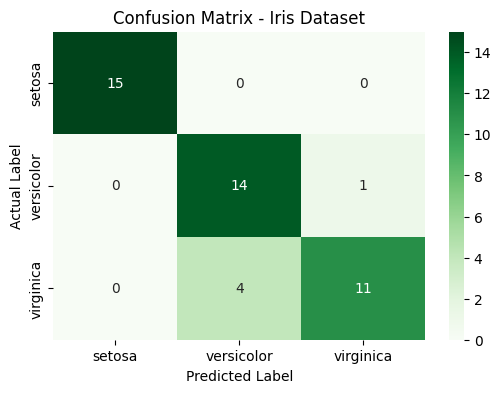

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load the Iris dataset
iris = load_iris()
X_clf = iris.data
y_clf = iris.target

# 2. Split into train and test sets
X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_clf, y_clf, test_size=0.3, random_state=42, stratify=y_clf
)

# 3. Train the Random Forest Classifier
rf_iris = RandomForestClassifier(n_estimators=100, random_state=42)
rf_iris.fit(X_train_iris, y_train_iris)

# 4. Predict on the test set
y_pred_iris = rf_iris.predict(X_test_iris)

# 5. Evaluate the model
accuracy_iris = accuracy_score(y_test_iris, y_pred_iris)
print(f"Accuracy on Iris Test Set: {accuracy_iris:.4f}\n")
print("Classification Report:")
print(classification_report(y_test_iris, y_pred_iris, target_names=iris.target_names))

# 6. Plot the Confusion Matrix
cm_iris = confusion_matrix(y_test_iris, y_pred_iris)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_iris, annot=True, fmt='d', cmap='Greens',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title('Confusion Matrix - Iris Dataset')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

In [4]:
# Create a DataFrame of predictions for visualization
df_iris_results = pd.DataFrame(X_test_iris, columns=iris.feature_names)
df_iris_results['actual_target'] = y_test_iris
df_iris_results['predicted_target'] = y_pred_iris
df_iris_results['actual_name'] = df_iris_results['actual_target'].map(lambda x: iris.target_names[x])
df_iris_results['predicted_name'] = df_iris_results['predicted_target'].map(lambda x: iris.target_names[x])
df_iris_results['is_correct'] = df_iris_results['actual_target'] == df_iris_results['predicted_target']

display(df_iris_results.head(10))

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),actual_target,predicted_target,actual_name,predicted_name,is_correct
0,7.3,2.9,6.3,1.8,2,2,virginica,virginica,True
1,6.1,2.9,4.7,1.4,1,1,versicolor,versicolor,True
2,6.3,2.8,5.1,1.5,2,1,virginica,versicolor,False
3,6.3,3.3,4.7,1.6,1,1,versicolor,versicolor,True
4,6.1,3.0,4.9,1.8,2,2,virginica,virginica,True
5,6.7,3.1,5.6,2.4,2,2,virginica,virginica,True
6,5.5,2.3,4.0,1.3,1,1,versicolor,versicolor,True
7,5.6,2.5,3.9,1.1,1,1,versicolor,versicolor,True
8,5.4,3.4,1.7,0.2,0,0,setosa,setosa,True
9,6.9,3.1,5.1,2.3,2,2,virginica,virginica,True


### Visualizing Predictions with a Scatterplot
Let's plot the test set instances based on their petal length and width. We will highlight the predicted class using the marker color and indicate correct versus incorrect predictions using different marker shapes.

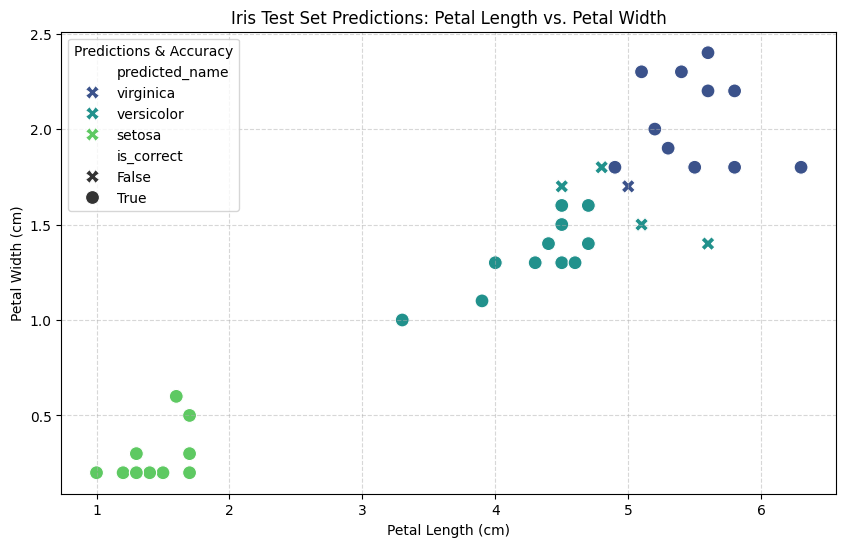

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot correct predictions with circles and incorrect predictions with 'X' markers
sns.scatterplot(
    data=df_iris_results,
    x='petal length (cm)',
    y='petal width (cm)',
    hue='predicted_name',
    style='is_correct',
    markers={True: 'o', False: 'X'},
    palette='viridis',
    s=100
)

plt.title('Iris Test Set Predictions: Petal Length vs. Petal Width')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.legend(title='Predictions & Accuracy')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()